Base Inside Airbnb RJ: 44111 imóveis (35288 treino | 8823 teste) | Alta Atratividade: 45.0%
Distância 1ª Amostra -> Euclidiana: 186.63 | Mahalanobis: 4.14

=== TAREFA 1: CLASSIFICAÇÃO DE ATRATIVIDADE ===
             Modelo de Classificação  Accuracy  Precision  Recall  F1-Score  ROC-AUC
             Baseline (Dummy - Moda)     0.550      0.000   0.000     0.000    0.500
     Regressão Logística (Otimizada)     0.769      0.749   0.733     0.741    0.852
               KNN Classifier (k=11)     0.760      0.723   0.756     0.739    0.832
          SVM Classifier (SVC - RBF)     0.766      0.738   0.743     0.741    0.850
      Árvore CART (ccp_alpha=0.0003)     0.771      0.729   0.785     0.756    0.849
            Bagging Classifier (OOB)     0.795      0.773   0.770     0.772    0.874
Random Forest Classifier (Otimizado)     0.792      0.778   0.754     0.766    0.875
              Extra Trees Classifier     0.771      0.776   0.690     0.731    0.856
                 AdaBoost Class

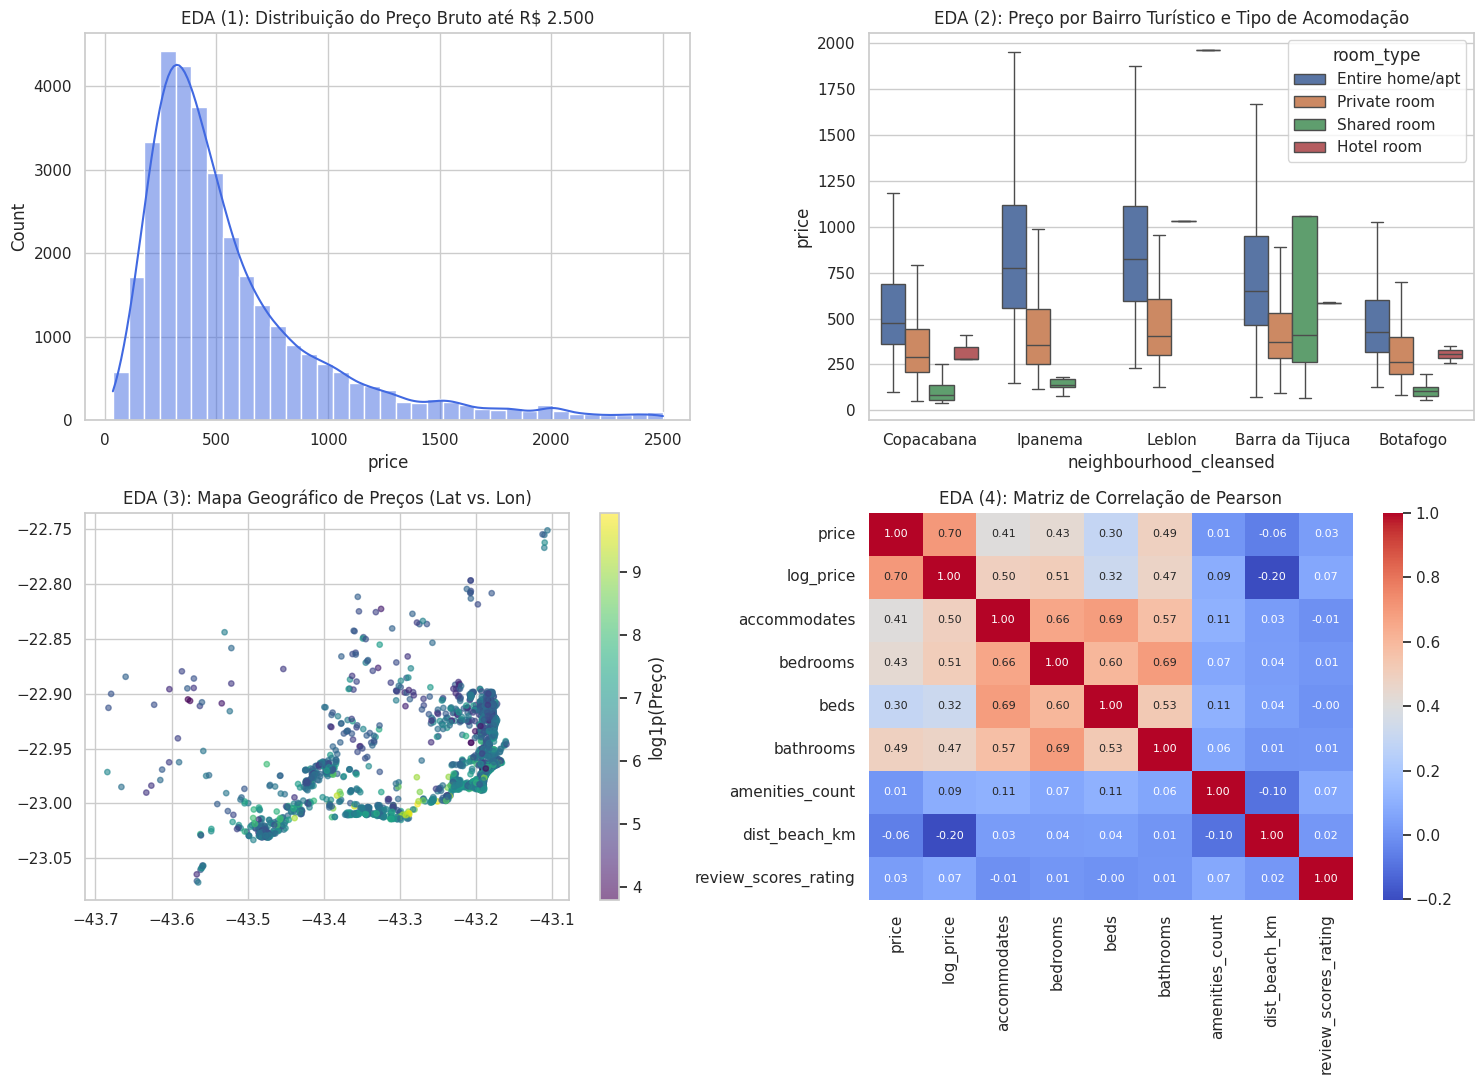

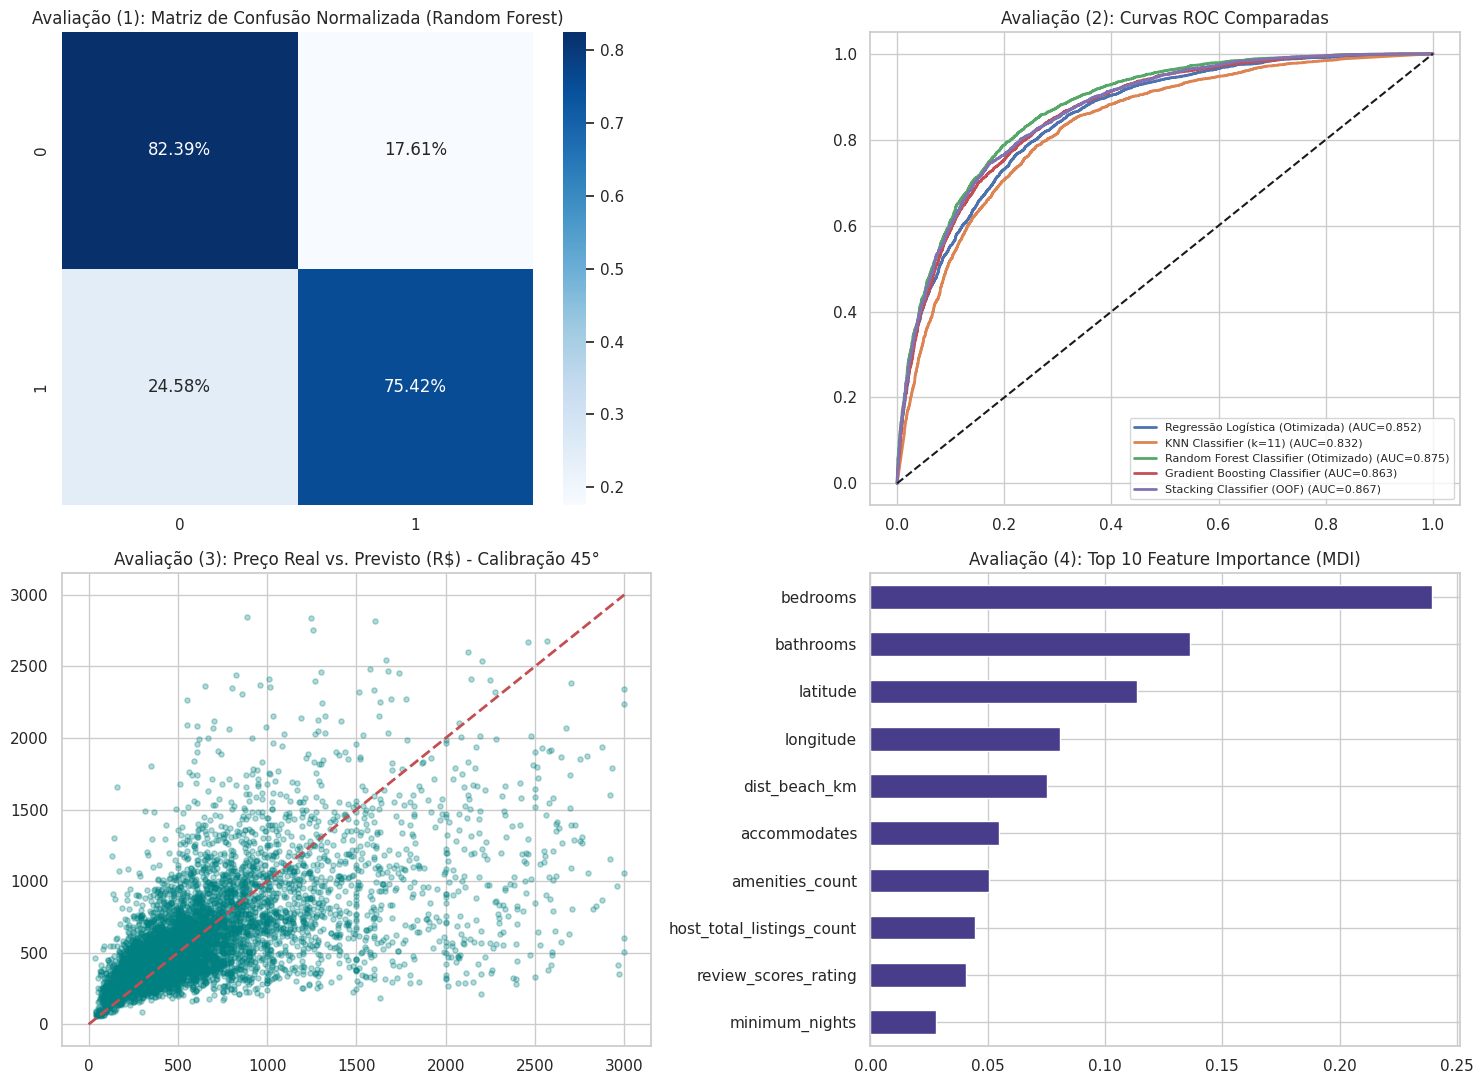

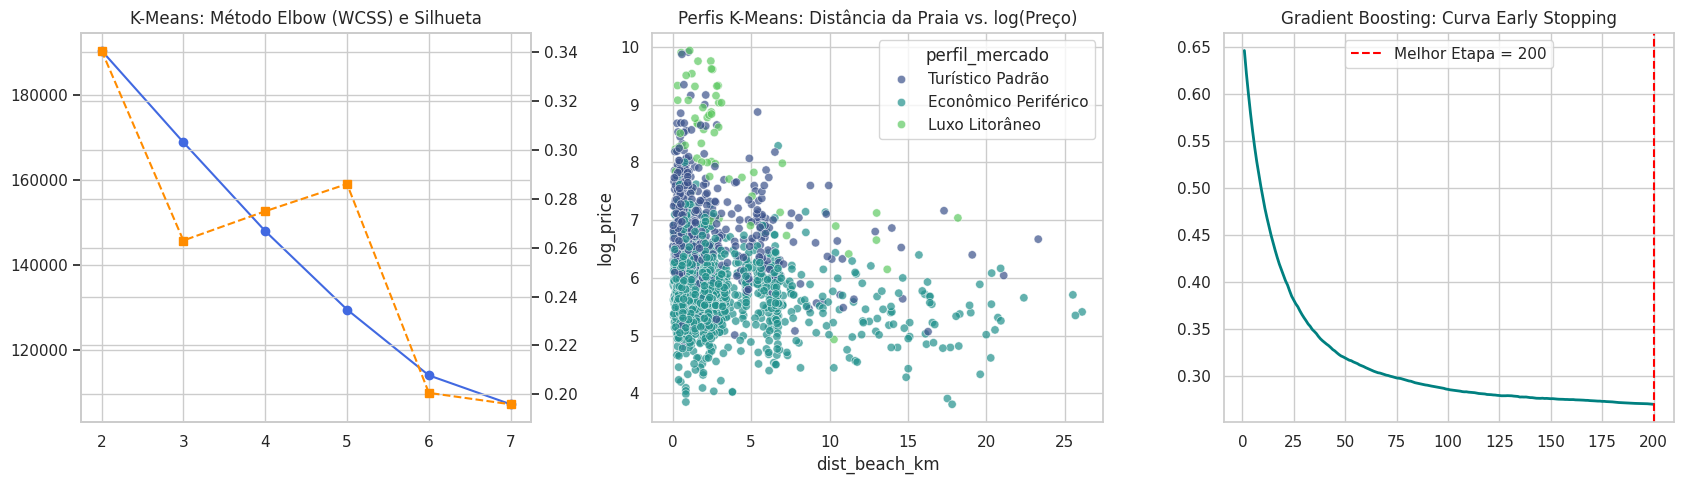

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import mahalanobis
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    BaggingClassifier, BaggingRegressor,
    ExtraTreesClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, GradientBoostingRegressor,
    VotingClassifier, VotingRegressor,
    StackingClassifier, StackingRegressor
)
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score
)

warnings.filterwarnings("ignore")
np.random.seed(42)

URL_AIRBNB_RJ = "https://data.insideairbnb.com/brazil/rj/rio-de-janeiro/2026-09-22/data/listings.csv.gz"
ORLA_RJ = np.array([
    [-22.9631, -43.1735], [-22.9711, -43.1825], [-22.9814, -43.1912],
    [-22.9865, -43.2045], [-22.9877, -43.2219], [-23.0003, -43.2658],
    [-23.0112, -43.3225], [-23.0125, -43.3650], [-23.0264, -43.4650], [-22.9286, -43.1718]
])
ZONA_SUL = {"Copacabana", "Ipanema", "Leblon", "Botafogo", "Flamengo", "Leme", "Laranjeiras", "Catete", "Glória", "Gávea", "Jardim Botânico", "Humaitá", "Lagoa", "Urca", "São Conrado", "Vidigal", "Rocinha"}
ZONA_OESTE = {"Barra da Tijuca", "Recreio dos Bandeirantes", "Jacarepaguá", "Joá", "Itanhangá", "Vargem Grande", "Vargem Pequena", "Guaratiba", "Campo Grande", "Camorim", "Curicica", "Freguesia (Jacarepaguá)", "Taquara", "Grumari"}
CENTRO = {"Centro", "Santa Teresa", "Lapa", "Saúde", "Gamboa", "Santo Cristo", "Estácio", "Catumbi", "Rio Comprido", "Cidade Nova", "Paquetá"}

df = pd.read_csv("listings.csv.gz" if os.path.exists("listings.csv.gz") else URL_AIRBNB_RJ, low_memory=False)
if not os.path.exists("listings.csv.gz"):
    df.to_csv("listings.csv.gz", index=False, compression="gzip")

if "bathrooms_text" in df.columns:
    bath_num = pd.to_numeric(df.get("bathrooms"), errors="coerce")
    txt = df["bathrooms_text"].fillna("").astype(str).str.lower()
    ext = txt.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    ext = np.where(txt.str.contains("half") & np.isnan(ext), 0.5, ext)
    df["bathrooms"] = np.where(bath_num.isna(), ext, bath_num)

if df.get("host_total_listings_count", pd.Series(dtype=float)).isna().all():
    df["host_total_listings_count"] = pd.to_numeric(df.get("host_listings_count", df.get("calculated_host_listings_count", 1)), errors="coerce")

df["price"] = pd.to_numeric(df["price"].astype(str).str.replace(r"[\$,R\s]", "", regex=True), errors="coerce")
df = df.dropna(subset=["price", "latitude", "longitude"]).drop_duplicates(subset=["id"])
df = df[(df["price"] >= 30.0) & (df["price"] <= 30000.0)].reset_index(drop=True)

df["reviews_per_month"] = pd.to_numeric(df["reviews_per_month"], errors="coerce").fillna(0.0)
df["availability_365"] = pd.to_numeric(df["availability_365"], errors="coerce").fillna(180.0).clip(0, 365)
ocup = (365.0 - df["availability_365"]) / 365.0
score_dem = (df["reviews_per_month"] > df["reviews_per_month"].median()) * 0.6 + (ocup >= ocup.median()) * 0.4 + (df["reviews_per_month"] / (df["reviews_per_month"].quantile(0.95) + 1e-5)).clip(0, 1) * 0.3

df["alta_atratividade"] = (score_dem >= np.quantile(score_dem, 0.55)).astype(int)
s_am = df["amenities"].fillna("").astype(str).str.strip()
df["amenities_count"] = np.where((s_am == "") | (s_am == "[]"), 0, s_am.str.count(",") + 1)
df["has_air_conditioning"] = s_am.str.lower().str.contains(r"air conditioning|ar-condicionado|\bac\b|split type", regex=True).astype(int)

dlat = (df["latitude"].values[:, None] - ORLA_RJ[:, 0]) * 111.32
dlon = (df["longitude"].values[:, None] - ORLA_RJ[:, 1]) * 111.32 * np.cos(np.radians(df["latitude"].values)[:, None])
df["dist_beach_km"] = np.min(np.sqrt(dlat ** 2 + dlon ** 2), axis=1)
df["macrorregiao"] = df["neighbourhood_cleansed"].apply(lambda b: "Zona Sul" if b in ZONA_SUL else ("Zona Oeste" if b in ZONA_OESTE else ("Centro" if b in CENTRO else "Zona Norte")))
df["log_price"] = np.log1p(df["price"])

df_train, df_test = train_test_split(df, test_size=0.20, random_state=42, stratify=df["alta_atratividade"])
df_train, df_test = df_train.copy(), df_test.copy()

moda_sh = df_train["host_is_superhost"].dropna().mode().iloc[0] if not df_train["host_is_superhost"].dropna().empty else "f"
for part in (df_train, df_test):
    part["superhost_bin"] = part["host_is_superhost"].fillna(moda_sh).astype(str).str.lower().str.startswith("t").astype(int)

for col in ["review_scores_rating", "bathrooms", "bedrooms", "beds", "minimum_nights", "host_total_listings_count"]:
    df_train[col] = pd.to_numeric(df_train[col], errors="coerce")
    df_test[col] = pd.to_numeric(df_test[col], errors="coerce")
    med_grp = df_train.groupby(["neighbourhood_cleansed", "room_type"])[col].median()
    med_glb = df_train[col].median()
    for part in (df_train, df_test):
        na_mask = part[col].isna()
        if na_mask.any():
            idx_zip = pd.MultiIndex.from_frame(part.loc[na_mask, ["neighbourhood_cleansed", "room_type"]])
            part.loc[na_mask, col] = med_grp.reindex(idx_zip).values
            part[col] = part[col].fillna(med_glb)

top_prop = df_train["property_type"].value_counts().nlargest(6).index
top_bairros = df_train["neighbourhood_cleansed"].value_counts().nlargest(10).index
for part in (df_train, df_test):
    part["bathrooms_per_guest"] = part["bathrooms"] / np.maximum(part["accommodates"], 1)
    part["property_type_grp"] = np.where(part["property_type"].isin(top_prop), part["property_type"], "Outros")
    part["bairro_grp"] = np.where(part["neighbourhood_cleansed"].isin(top_bairros), part["neighbourhood_cleansed"], "Outros_" + part["macrorregiao"])

amostra_cov = df_train[["accommodates", "bathrooms", "amenities_count", "dist_beach_km", "price"]].dropna().sample(2000, random_state=42).values
cov_mat = np.cov(amostra_cov, rowvar=False)
prec_mat = np.linalg.pinv(cov_mat)
centro_m = amostra_cov.mean(axis=0)
print(f"Base Inside Airbnb RJ: {len(df)} imóveis ({len(df_train)} treino | {len(df_test)} teste) | Alta Atratividade: {df['alta_atratividade'].mean()*100:.1f}%")
print(f"Distância 1ª Amostra -> Euclidiana: {np.linalg.norm(amostra_cov[0] - centro_m):.2f} | Mahalanobis: {mahalanobis(amostra_cov[0], centro_m, prec_mat):.2f}")

cols_num_reg = ["latitude", "longitude", "accommodates", "bathrooms", "bedrooms", "beds", "amenities_count", "has_air_conditioning", "bathrooms_per_guest", "dist_beach_km", "minimum_nights", "review_scores_rating", "superhost_bin", "host_total_listings_count"]
cols_num_clf = cols_num_reg + ["log_price"]
cols_cat = ["room_type", "macrorregiao", "property_type_grp", "bairro_grp"]

prep_clf = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cols_num_clf),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cols_cat)
])
prep_reg = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cols_num_reg),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cols_cat)
])

X_tr_clf = prep_clf.fit_transform(df_train[cols_num_clf + cols_cat])
X_te_clf = prep_clf.transform(df_test[cols_num_clf + cols_cat])
y_tr_clf, y_te_clf = df_train["alta_atratividade"].values, df_test["alta_atratividade"].values
nomes_feat_clf = cols_num_clf + list(prep_clf.named_transformers_["cat"].get_feature_names_out(cols_cat))

X_tr_reg = prep_reg.fit_transform(df_train[cols_num_reg + cols_cat])
X_te_reg = prep_reg.transform(df_test[cols_num_reg + cols_cat])
y_tr_log, y_te_log = df_train["log_price"].values, df_test["log_price"].values
y_te_reais = df_test["price"].values
nomes_feat_reg = cols_num_reg + list(prep_reg.named_transformers_["cat"].get_feature_names_out(cols_cat))

X_sub_tr, X_sub_val, y_sub_tr, y_sub_val = train_test_split(X_tr_clf, y_tr_clf, test_size=0.1875, random_state=42, stratify=y_tr_clf)
X_grid_c, _, y_grid_c, _ = train_test_split(X_tr_clf, y_tr_clf, train_size=3500, random_state=42, stratify=y_tr_clf)
X_fast_c, _, y_fast_c, _ = train_test_split(X_tr_clf, y_tr_clf, train_size=10000, random_state=42, stratify=y_tr_clf)

caminho_poda = DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42).cost_complexity_pruning_path(X_grid_c, y_grid_c)
alphas_cand = np.unique(np.quantile(caminho_poda.ccp_alphas[caminho_poda.ccp_alphas >= 0], np.linspace(0, 0.8, 6)))
melhor_alpha = max(alphas_cand, key=lambda a: f1_score(y_sub_val, DecisionTreeClassifier(ccp_alpha=float(a), max_depth=10, random_state=42).fit(X_grid_c, y_grid_c).predict(X_sub_val)))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gs_log = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42), {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"]}, cv=skf, scoring="f1", n_jobs=-1).fit(X_grid_c, y_grid_c)
gs_knn = GridSearchCV(KNeighborsClassifier(n_jobs=-1), {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]}, cv=skf, scoring="f1", n_jobs=-1).fit(X_grid_c, y_grid_c)
gs_rf_c = GridSearchCV(RandomForestClassifier(max_features="sqrt", random_state=42, n_jobs=-1), {"n_estimators": [100, 150], "max_depth": [10, 18], "min_samples_split": [2, 5]}, cv=skf, scoring="f1", n_jobs=-1).fit(X_grid_c, y_grid_c)

classificadores = {
    "Baseline (Dummy - Moda)": (DummyClassifier(strategy="most_frequent"), X_tr_clf, y_tr_clf),
    "Regressão Logística (Otimizada)": (LogisticRegression(**gs_log.best_params_, max_iter=1000, random_state=42), X_tr_clf, y_tr_clf),
    f"KNN Classifier (k={gs_knn.best_params_['n_neighbors']})": (KNeighborsClassifier(**gs_knn.best_params_, n_jobs=-1), X_fast_c, y_fast_c),
    "SVM Classifier (SVC - RBF)": (SVC(kernel="rbf", C=1.0, random_state=42), X_grid_c, y_grid_c),
    f"Árvore CART (ccp_alpha={melhor_alpha:.4f})": (DecisionTreeClassifier(ccp_alpha=float(melhor_alpha), max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=42), X_tr_clf, y_tr_clf),
    "Bagging Classifier (OOB)": (BaggingClassifier(DecisionTreeClassifier(max_depth=14, random_state=42), n_estimators=80, max_samples=0.8, oob_score=True, n_jobs=-1, random_state=42), X_fast_c, y_fast_c),
    "Random Forest Classifier (Otimizado)": (RandomForestClassifier(**gs_rf_c.best_params_, max_features="sqrt", oob_score=True, random_state=42, n_jobs=-1), X_tr_clf, y_tr_clf),
    "Extra Trees Classifier": (ExtraTreesClassifier(n_estimators=120, max_depth=16, random_state=42, n_jobs=-1), X_tr_clf, y_tr_clf),
    "AdaBoost Classifier": (AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=42), n_estimators=100, learning_rate=0.5, random_state=42), X_fast_c, y_fast_c),
    "Gradient Boosting Classifier": (GradientBoostingClassifier(n_estimators=140, learning_rate=0.05, max_depth=2, random_state=42), X_fast_c, y_fast_c),
    "Voting Classifier (Soft)": (VotingClassifier([("log", LogisticRegression(max_iter=1000)), ("knn", KNeighborsClassifier(7)), ("rf", RandomForestClassifier(100, max_depth=14, random_state=42))], voting="soft", n_jobs=-1), X_fast_c, y_fast_c),
    "Stacking Classifier (OOF)": (StackingClassifier([("rf", RandomForestClassifier(80, max_depth=12, random_state=42)), ("knn", KNeighborsClassifier(7))], final_estimator=LogisticRegression(), cv=5, n_jobs=-1), X_grid_c, y_grid_c)
}

res_clf, preds_clf, probs_clf = [], {}, {}
for nome, (mod, X_f, y_f) in classificadores.items():
    mod.fit(X_f, y_f)
    p = mod.predict(X_te_clf)
    pr = mod.predict_proba(X_te_clf)[:, 1] if hasattr(mod, "predict_proba") else (lambda s: (s - s.min()) / (s.max() - s.min() + 1e-8))(mod.decision_function(X_te_clf))
    preds_clf[nome], probs_clf[nome] = p, pr
    res_clf.append({"Modelo de Classificação": nome, "Accuracy": accuracy_score(y_te_clf, p), "Precision": precision_score(y_te_clf, p, zero_division=0), "Recall": recall_score(y_te_clf, p, zero_division=0), "F1-Score": f1_score(y_te_clf, p, zero_division=0), "ROC-AUC": roc_auc_score(y_te_clf, pr)})

print("\n=== TAREFA 1: CLASSIFICAÇÃO DE ATRATIVIDADE ===")
print(pd.DataFrame(res_clf).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

idx_g = np.random.default_rng(42).choice(len(X_tr_reg), 3500, replace=False)
idx_f = np.random.default_rng(42).choice(len(X_tr_reg), 10000, replace=False)
X_grid_r, y_grid_r = X_tr_reg[idx_g], y_tr_log[idx_g]
X_fast_r, y_fast_r = X_tr_reg[idx_f], y_tr_log[idx_f]

X_str_r, X_sval_r, y_str_r, y_sval_r = train_test_split(X_fast_r, y_fast_r, test_size=0.20, random_state=42)
gb_full = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.85, random_state=42).fit(X_str_r, y_str_r)
mse_etapas = [mean_squared_error(y_sval_r, pred_s) for pred_s in gb_full.staged_predict(X_sval_r)]
melhor_n_gb = int(np.argmin(mse_etapas)) + 1

gs_rf_r = GridSearchCV(RandomForestRegressor(min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1), {"n_estimators": [100, 150], "max_depth": [12, 20], "min_samples_split": [2, 5]}, cv=KFold(5, shuffle=True, random_state=42), scoring="r2", n_jobs=-1).fit(X_grid_r, y_grid_r)

regressores = {
    "Baseline (Média)": (DummyRegressor(strategy="mean"), X_tr_reg, y_tr_log),
    "Regressão Linear Múltipla": (LinearRegression(), X_tr_reg, y_tr_log),
    "KNN Regressor (k=7)": (KNeighborsRegressor(n_neighbors=7, weights="distance", n_jobs=-1), X_fast_r, y_fast_r),
    "SVR (Kernel RBF)": (make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0, epsilon=0.15)), X_grid_r, y_grid_r),
    "Árvore CART Regressor": (DecisionTreeRegressor(max_depth=10, min_samples_leaf=4, random_state=42), X_tr_reg, y_tr_log),
    "Bagging Regressor (OOB)": (BaggingRegressor(DecisionTreeRegressor(max_depth=14, random_state=42), n_estimators=80, max_samples=0.8, oob_score=True, n_jobs=-1, random_state=42), X_fast_r, y_fast_r),
    "Random Forest Regressor (Otimizado)": (RandomForestRegressor(**gs_rf_r.best_params_, min_samples_leaf=2, max_features=0.7, random_state=42, n_jobs=-1), X_fast_r, y_fast_r),
    f"Gradient Boosting (Early Stop={melhor_n_gb})": (GradientBoostingRegressor(n_estimators=melhor_n_gb, learning_rate=0.05, max_depth=3, subsample=0.85, random_state=42), X_fast_r, y_fast_r),
    "Voting Regressor": (VotingRegressor([("lin", LinearRegression()), ("knn", KNeighborsRegressor(7)), ("rf", RandomForestRegressor(80, max_depth=14, max_features="sqrt", random_state=42))], n_jobs=-1), X_fast_r, y_fast_r),
    "Stacking Regressor (OOF)": (StackingRegressor([("rf", RandomForestRegressor(80, max_depth=12, max_features="sqrt", random_state=42)), ("knn", KNeighborsRegressor(7)), ("svr", SVR(C=5.0, epsilon=0.15))], final_estimator=LinearRegression(), cv=5, n_jobs=-1), X_grid_r, y_grid_r)
}

res_reg, preds_reg_reais = [], {}
for nome, (reg, X_f, y_f) in regressores.items():
    reg.fit(X_f, y_f)
    p_log = np.clip(reg.predict(X_te_reg), np.log1p(20.0), np.log1p(35000.0))
    p_reais = np.expm1(p_log)
    preds_reg_reais[nome] = p_reais
    res_reg.append({"Modelo de Regressão": nome, "MAE (R$)": mean_absolute_error(y_te_reais, p_reais), "RMSE (R$)": np.sqrt(mean_squared_error(y_te_reais, p_reais)), "R² Score": r2_score(y_te_log, p_log)})

print("\n=== TAREFA 2: REGRESSÃO DO PREÇO DA DIÁRIA (R$) ===")
print(pd.DataFrame(res_reg).to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"Vetores de Suporte SVR: {len(regressores['SVR (Kernel RBF)'][0].named_steps['svr'].support_)} | Score OOB RF Clf: {classificadores['Random Forest Classifier (Otimizado)'][0].oob_score_:.3f}")

cols_km = ["log_price", "accommodates", "bedrooms", "bathrooms", "amenities_count", "dist_beach_km", "review_scores_rating"]
sc_km = StandardScaler()
X_km = sc_km.fit_transform(df_train[cols_km])
X_km_sil = X_km[np.random.default_rng(42).choice(len(X_km), 2500, replace=False)]

ks = list(range(2, 8))
wcss, sils = [], []
for k in ks:
    km_t = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_km)
    wcss.append(km_t.inertia_)
    sils.append(silhouette_score(X_km_sil, km_t.predict(X_km_sil)))

km_final = KMeans(n_clusters=3, init="k-means++", n_init=20, random_state=42)
df_train["cluster"] = km_final.fit_predict(X_km)
ordem_c = df_train.groupby("cluster")["price"].mean().sort_values().index.tolist()
mapa_c = {ordem_c[0]: "Econômico Periférico", ordem_c[1]: "Turístico Padrão", ordem_c[2]: "Luxo Litorâneo"}
df_train["perfil_mercado"] = df_train["cluster"].map(mapa_c)

print("\n=== TAREFA 3: SEGMENTAÇÃO K-MEANS (3 PERFIS DE MERCADO) ===")
print(df_train.groupby("perfil_mercado")[["price", "accommodates", "bedrooms", "amenities_count", "dist_beach_km", "review_scores_rating"]].mean().loc[["Econômico Periférico", "Turístico Padrão", "Luxo Litorâneo"]].to_string(float_format=lambda x: f"{x:.2f}"))

rf_clf_mod = classificadores["Random Forest Classifier (Otimizado)"][0]
rf_reg_mod = regressores["Random Forest Regressor (Otimizado)"][0]
perm_imp = permutation_importance(rf_clf_mod, X_te_clf[:800], y_te_clf[:800], n_repeats=3, random_state=42, scoring="f1", n_jobs=-1)
df_imp = pd.DataFrame({"MDI (Gini)": rf_clf_mod.feature_importances_, "Permutation (F1)": perm_imp.importances_mean}, index=nomes_feat_clf).sort_values("MDI (Gini)", ascending=False).head(8)
print("\n=== TOP 8 ATRIBUTOS (MDI vs. PERMUTATION IMPORTANCE) ===")
print(df_imp.to_string(float_format=lambda x: f"{x:.4f}"))

sns.set_theme(style="whitegrid")
fig1, ax1 = plt.subplots(2, 2, figsize=(15, 11))
sns.histplot(df_train[df_train["price"] <= 2500]["price"], kde=True, bins=35, color="royalblue", ax=ax1[0, 0])
ax1[0, 0].set_title("EDA (1): Distribuição do Preço Bruto até R$ 2.500")
sns.boxplot(data=df_train[df_train["neighbourhood_cleansed"].isin(["Copacabana", "Ipanema", "Leblon", "Barra da Tijuca", "Botafogo"]) & (df_train["price"] <= 3000)], x="neighbourhood_cleansed", y="price", hue="room_type", ax=ax1[0, 1], showfliers=False)
ax1[0, 1].set_title("EDA (2): Preço por Bairro Turístico e Tipo de Acomodação")
am_g = df_train.sample(3000, random_state=42)
sc_g = ax1[1, 0].scatter(am_g["longitude"], am_g["latitude"], c=am_g["log_price"], cmap="viridis", alpha=0.6, s=15)
plt.colorbar(sc_g, ax=ax1[1, 0], label="log1p(Preço)")
ax1[1, 0].set_title("EDA (3): Mapa Geográfico de Preços (Lat vs. Lon)")
sns.heatmap(df_train[["price", "log_price", "accommodates", "bedrooms", "beds", "bathrooms", "amenities_count", "dist_beach_km", "review_scores_rating"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax1[1, 1], annot_kws={"size": 8})
ax1[1, 1].set_title("EDA (4): Matriz de Correlação de Pearson")
plt.tight_layout()
plt.savefig("eda_diagnostico_turismo_rj.png", dpi=150)
plt.show()

fig2, ax2 = plt.subplots(2, 2, figsize=(15, 11))
sns.heatmap(confusion_matrix(y_te_clf, preds_clf["Random Forest Classifier (Otimizado)"], normalize="true"), annot=True, fmt=".2%", cmap="Blues", ax=ax2[0, 0])
ax2[0, 0].set_title("Avaliação (1): Matriz de Confusão Normalizada (Random Forest)")
for nm in ["Regressão Logística (Otimizada)", f"KNN Classifier (k={gs_knn.best_params_['n_neighbors']})", "Random Forest Classifier (Otimizado)", "Gradient Boosting Classifier", "Stacking Classifier (OOF)"]:
    fpr, tpr, _ = roc_curve(y_te_clf, probs_clf[nm])
    ax2[0, 1].plot(fpr, tpr, lw=2, label=f"{nm} (AUC={roc_auc_score(y_te_clf, probs_clf[nm]):.3f})")
ax2[0, 1].plot([0, 1], [0, 1], "k--")
ax2[0, 1].legend(fontsize=8)
ax2[0, 1].set_title("Avaliação (2): Curvas ROC Comparadas")
m_v = (y_te_reais <= 3000) & (preds_reg_reais["Random Forest Regressor (Otimizado)"] <= 3000)
ax2[1, 0].scatter(y_te_reais[m_v], preds_reg_reais["Random Forest Regressor (Otimizado)"][m_v], alpha=0.3, color="teal", s=14)
ax2[1, 0].plot([0, 3000], [0, 3000], "r--", lw=2)
ax2[1, 0].set_title("Avaliação (3): Preço Real vs. Previsto (R$) - Calibração 45°")
pd.Series(rf_reg_mod.feature_importances_, index=nomes_feat_reg).nlargest(10).sort_values().plot.barh(ax=ax2[1, 1], color="darkslateblue")
ax2[1, 1].set_title("Avaliação (4): Top 10 Feature Importance (MDI)")
plt.tight_layout()
plt.savefig("avaliacao_modelos_turismo_rj.png", dpi=150)
plt.show()

fig3, ax3 = plt.subplots(1, 3, figsize=(17, 5))
ax3[0].plot(ks, wcss, "o-", color="royalblue", label="WCSS")
ax3_t = ax3[0].twinx()
ax3_t.plot(ks, sils, "s--", color="darkorange", label="Silhueta")
ax3[0].set_title("K-Means: Método Elbow (WCSS) e Silhueta")
sns.scatterplot(data=df_train.sample(2500, random_state=42), x="dist_beach_km", y="log_price", hue="perfil_mercado", palette="viridis", ax=ax3[1], alpha=0.7)
ax3[1].set_title("Perfis K-Means: Distância da Praia vs. log(Preço)")
ax3[2].plot(range(1, len(mse_etapas) + 1), mse_etapas, color="teal", lw=2)
ax3[2].axvline(melhor_n_gb, color="red", linestyle="--", label=f"Melhor Etapa = {melhor_n_gb}")
ax3[2].legend()
ax3[2].set_title("Gradient Boosting: Curva Early Stopping")
plt.tight_layout()
plt.savefig("clusters_e_early_stopping_rj.png", dpi=150)
plt.show()
